#Name: Muhammad Bilal


#Reg No: FA23-BAI-029

Task1

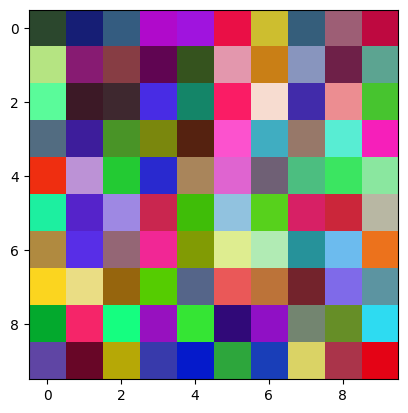

Data: (200, 3) 0.005061583846218687 0.9997176732861306
Weights: (10, 10, 3) 0.004632023004602859 0.9968742518459474


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
data = np.random.rand(200, 3)
weights = np.random.rand(10, 10, 3)

plt.imshow(weights)
plt.show()

print("Data:", data.shape, data.min(), data.max())
print("Weights:", weights.shape, weights.min(), weights.max())

Task2

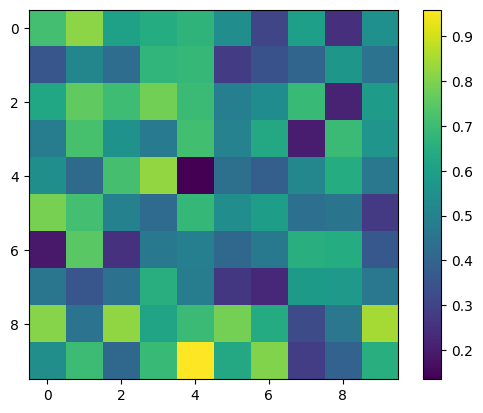

Min distance: 0.13437863807304615
Position: (np.int64(4), np.int64(4))


In [ ]:
def euclidean_distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2, axis=-1))

sample = data[np.random.randint(0, len(data))]
distances = euclidean_distance(weights, sample)

plt.imshow(distances, cmap='viridis')
plt.colorbar()
plt.show()

min_idx = np.unravel_index(np.argmin(distances), distances.shape)
print("Min distance:", distances[min_idx])
print("Position:", min_idx)

Task3

Sample 0: BMU=(np.int64(3), np.int64(8)), Dist=0.1041
Sample 1: BMU=(np.int64(7), np.int64(7)), Dist=0.1484
Sample 2: BMU=(np.int64(5), np.int64(0)), Dist=0.0979
Sample 3: BMU=(np.int64(0), np.int64(4)), Dist=0.1395
Sample 4: BMU=(np.int64(5), np.int64(8)), Dist=0.0859


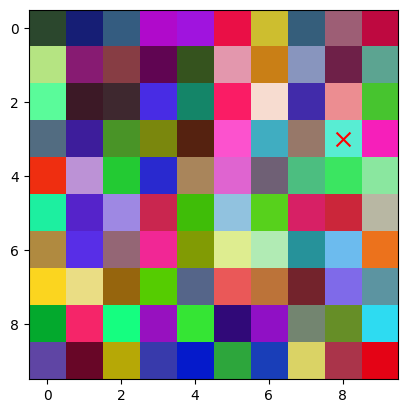

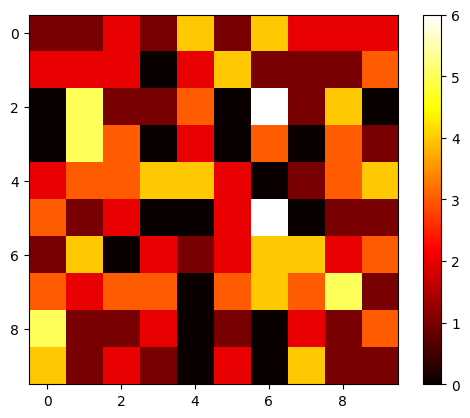

In [ ]:
def find_bmu(weights, x):
    dists = euclidean_distance(weights, x)
    return np.unravel_index(np.argmin(dists), dists.shape)

for i in range(5):
    s = data[i]
    bmu_pos = find_bmu(weights, s)
    dist = euclidean_distance(weights[bmu_pos], s)
    print(f"Sample {i}: BMU={bmu_pos}, Dist={dist:.4f}")

single_sample = data[0]
single_bmu = find_bmu(weights, single_sample)
plt.imshow(weights)
plt.scatter(single_bmu[1], single_bmu[0], color='red', marker='x', s=100)
plt.show()

hit_map = np.zeros((10, 10))
for s in data:
    bmu_pos = find_bmu(weights, s)
    hit_map[bmu_pos] += 1

plt.imshow(hit_map, cmap='hot')
plt.colorbar()
plt.show()

Task4

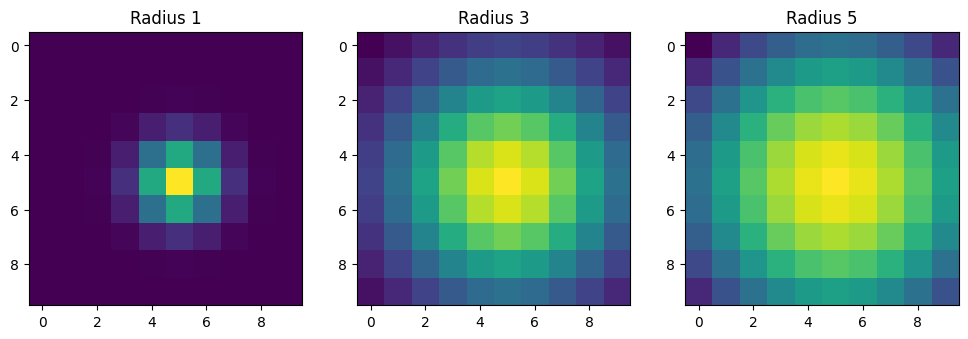

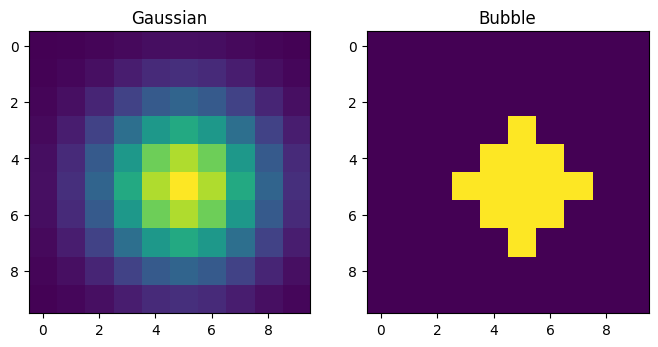

At BMU: 1.0
3 steps away: 0.32465246735834974


In [ ]:
def neighborhood(grid_size, bmu, radius):
    y, x = np.ogrid[0:grid_size[0], 0:grid_size[1]]
    d_sq = (x - bmu[1])**2 + (y - bmu[0])**2
    return np.exp(-d_sq / (2 * (radius**2)))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, r in enumerate([1, 3, 5]):
    h = neighborhood((10, 10), (5, 5), r)
    axes[i].imshow(h, cmap='viridis')
    axes[i].set_title(f"Radius {r}")
plt.show()

def bubble_neighborhood(grid_size, bmu, radius):
    y, x = np.ogrid[0:grid_size[0], 0:grid_size[1]]
    d = np.sqrt((x - bmu[1])**2 + (y - bmu[0])**2)
    return (d <= radius).astype(float)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(neighborhood((10, 10), (5, 5), 2), cmap='viridis')
axes[0].set_title("Gaussian")
axes[1].imshow(bubble_neighborhood((10, 10), (5, 5), 2), cmap='viridis')
axes[1].set_title("Bubble")
plt.show()

h_vals = neighborhood((10, 10), (5, 5), 2)
print("At BMU:", h_vals[5, 5])
print("3 steps away:", h_vals[5, 8])

Task5

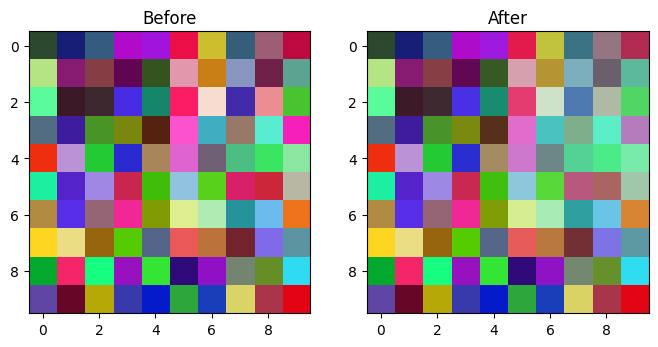

Total absolute change: 8.68310343621436
Dist before: 0.1041, Dist after: 0.0520
Distance decreased


In [ ]:
def update_weights(weights, x, bmu, learning_rate, radius):
    h = neighborhood(weights.shape[:2], bmu, radius)[..., np.newaxis]
    return weights + learning_rate * h * (x - weights)

sample_t5 = data[0]
bmu_t5 = find_bmu(weights, sample_t5)
new_weights = update_weights(weights, sample_t5, bmu_t5, 0.5, 2.0)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(weights)
axes[0].set_title("Before")
axes[1].imshow(new_weights)
axes[1].set_title("After")
plt.show()

change = np.sum(np.abs(new_weights - weights))
print("Total absolute change:", change)

dist_before = euclidean_distance(weights[bmu_t5], sample_t5)
dist_after = euclidean_distance(new_weights[bmu_t5], sample_t5)
print(f"Dist before: {dist_before:.4f}, Dist after: {dist_after:.4f}")
if dist_after < dist_before:
    print("Distance decreased")

Task6

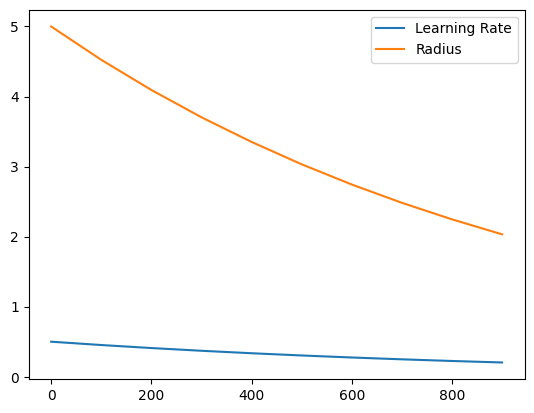

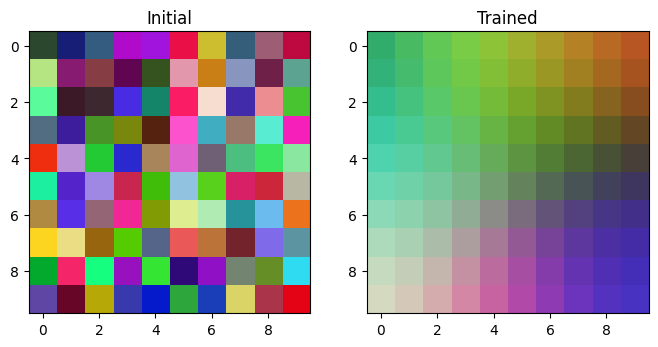

In [ ]:
def train_som(data, grid_size, iterations, lr_start, radius_start):
    w = np.random.rand(grid_size[0], grid_size[1], data.shape[1])
    lr_history, r_history = [], []
    for t in range(iterations):
        decay = np.exp(-t / iterations)
        lr = lr_start * decay
        r = radius_start * decay
        if t % 100 == 0:
            lr_history.append(lr)
            r_history.append(r)
        x = data[np.random.randint(0, len(data))]
        bmu = find_bmu(w, x)
        w = update_weights(w, x, bmu, lr, r)
    return w, lr_history, r_history

trained_weights, lrs, rs = train_som(data, (10, 10), 1000, 0.5, 5.0)

plt.plot(np.arange(0, 1000, 100), lrs, label="Learning Rate")
plt.plot(np.arange(0, 1000, 100), rs, label="Radius")
plt.legend()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(weights)
axes[0].set_title("Initial")
axes[1].imshow(trained_weights)
axes[1].set_title("Trained")
plt.savefig("task6_result.png")
plt.show()

Task7

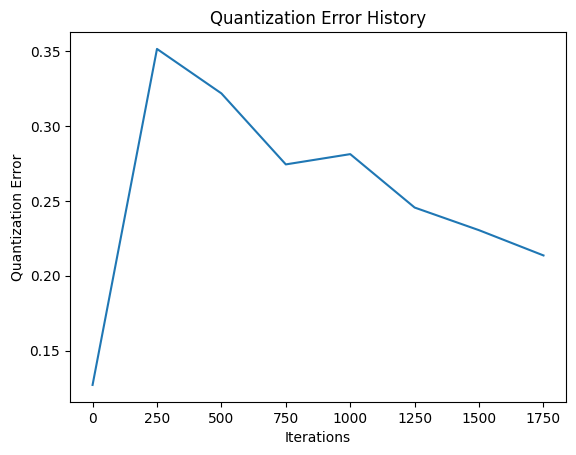

First Error: 0.1272, Last Error: 0.2136, Reduction: -67.90%


In [ ]:
def quantization_error(data, weights):
    total_dist = 0
    for x in data:
        bmu = find_bmu(weights, x)
        total_dist += euclidean_distance(weights[bmu], x)
    return total_dist / len(data)

def train_som_qe(data, grid_size, iterations, lr_start, radius_start):
    w = np.random.rand(grid_size[0], grid_size[1], data.shape[1])
    qe_history = []
    for t in range(iterations):
        decay = np.exp(-t / iterations)
        lr = lr_start * decay
        r = radius_start * decay
        if t % 250 == 0:
            qe_history.append(quantization_error(data, w))
        x = data[np.random.randint(0, len(data))]
        bmu = find_bmu(w, x)
        w = update_weights(w, x, bmu, lr, r)
    return w, qe_history

trained_w_qe, qes = train_som_qe(data, (10, 10), 2000, 0.5, 5.0)

plt.plot(np.arange(0, 2000, 250), qes)
plt.xlabel("Iterations")
plt.ylabel("Quantization Error")
plt.title("Quantization Error History")
plt.show()

first_err, last_err = qes[0], qes[-1]
reduction = (first_err - last_err) / first_err * 100
print(f"First Error: {first_err:.4f}, Last Error: {last_err:.4f}, Reduction: {reduction:.2f}%")

Task8

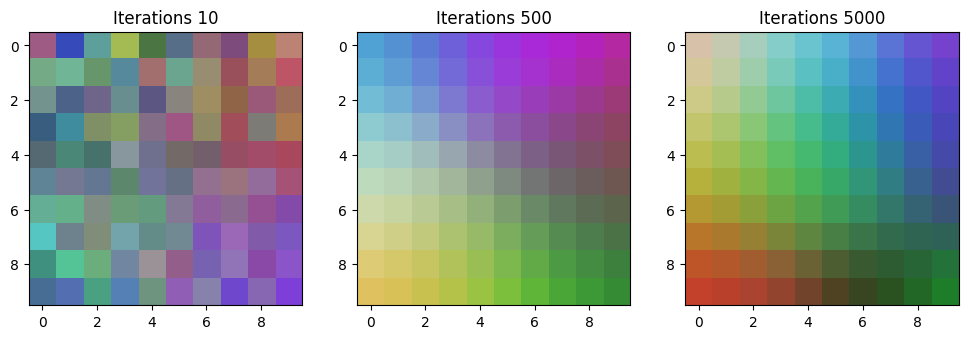

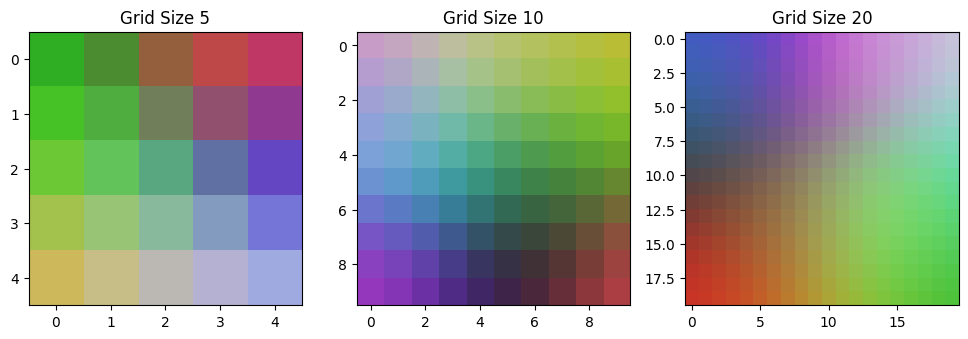

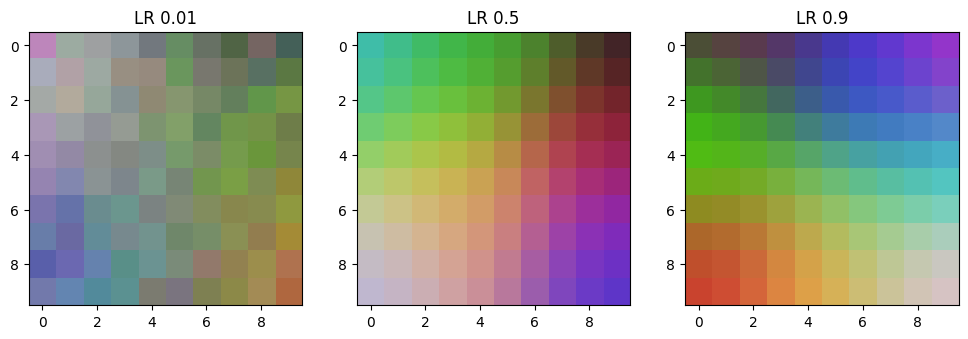

Setting Name        Value     Final Error
Iterations          10        0.2540
Iterations          500       0.2332
Iterations          5000      0.1963
Grid Size           5         0.2366
Grid Size           10        0.2022
Grid Size           20        0.2032
Learning Rate       0.01      0.2838
Learning Rate       0.5       0.1957
Learning Rate       0.9       0.1877


In [ ]:
summary = []

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, iters in enumerate([10, 500, 5000]):
    w, _ = train_som_qe(data, (10, 10), iters, 0.5, 5.0)
    axes[i].imshow(w)
    axes[i].set_title(f"Iterations {iters}")
    summary.append(("Iterations", iters, quantization_error(data, w)))
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, size in enumerate([5, 10, 20]):
    w, _ = train_som_qe(data, (size, size), 1000, 0.5, size / 2)
    axes[i].imshow(w)
    axes[i].set_title(f"Grid Size {size}")
    summary.append(("Grid Size", size, quantization_error(data, w)))
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, lr in enumerate([0.01, 0.5, 0.9]):
    w, _ = train_som_qe(data, (10, 10), 1000, lr, 5.0)
    axes[i].imshow(w)
    axes[i].set_title(f"LR {lr}")
    summary.append(("Learning Rate", lr, quantization_error(data, w)))
plt.show()

print(f"{'Setting Name':<20}{'Value':<10}{'Final Error':<10}")
for name, val, err in summary:
    print(f"{name:<20}{val:<10}{err:.4f}")

Task9

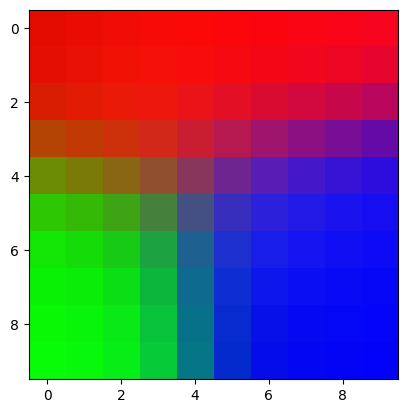

Neurons with at least one sample: 38


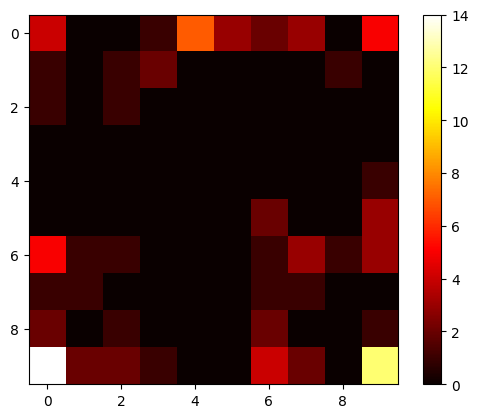

In [ ]:
base_colors = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1]])
noisy_data = []
for _ in range(100):
    base = base_colors[np.random.randint(0, 3)]
    noisy = np.clip(base + np.random.normal(0, 0.1, 3), 0, 1)
    noisy_data.append(noisy)
noisy_data = np.array(noisy_data)

trained_noisy_w, _ = train_som_qe(noisy_data, (10, 10), 2000, 0.5, 5.0)
plt.imshow(trained_noisy_w)
plt.show()

groups = {}
for s in noisy_data:
    bmu = find_bmu(trained_noisy_w, s)
    if bmu not in groups:
        groups[bmu] = []
    groups[bmu].append(s)

print("Neurons with at least one sample:", len(groups))

hit_map_noisy = np.zeros((10, 10))
for bmu, samples in groups.items():
    hit_map_noisy[bmu] = len(samples)

plt.imshow(hit_map_noisy, cmap='hot')
plt.colorbar()
plt.show()